# 03 · Preprocesamiento: capa base

**Objetivo:** dejar el texto listo para cualquier técnica de NLP, sin comprometernos todavía con una historia. Aplicamos las decisiones del EDA (`02_eda.ipynb`, sección 10) que no dependen de la historia:

| Paso | Qué hace | Decisión del EDA |
|---|---|---|
| 1 | Excluir notas sin texto y marcar plantillas | #1, #2 |
| 2 | Limpiar URLs, correos, teléfonos; normalizar Unicode, comillas y espacios | #3 |
| 3 | Lematizar, etiquetar categorías gramaticales y extraer entidades con spaCy | #5, #6 |
| 4 | Quitar stopwords generales y del dominio | #4 |
| 5 | Unir frases de dos palabras ("medio_ambiente") | #6 |

**Salida:** `data/processed/noticias_base.parquet`, con todas las columnas originales más:

- `texto_limpio`: texto limpio con mayúsculas y puntuación (para NER o *embeddings*).
- `lemas`: lemas de palabras con contenido, sin stopwords.
- `lemas_frases`: lo mismo con las frases unidas (para modelado de temas o TF-IDF).
- `ent_texto`, `ent_tipo`: entidades nombradas detectadas por spaCy.
- `es_plantilla`: avisos recurrentes que conviene excluir del modelado de temas.

**Tiempo:** el paso de spaCy tarda ~15 min la primera vez. El resultado se guarda en `data/interim/` y las siguientes ejecuciones lo leen de ahí.

## 0. Configuración

In [1]:
import re
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import spacy
from nltk.corpus import stopwords

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from preprocesamiento import detectar_frases, limpiar_texto, procesar_spacy, unir_frases

ENTRADA = RAIZ / "data" / "processed" / "noticias.parquet"
CACHE_SPACY = RAIZ / "data" / "interim" / "spacy.parquet"
SALIDA = RAIZ / "data" / "processed" / "noticias_base.parquet"
CACHE_SPACY.parent.mkdir(parents=True, exist_ok=True)

MODELO_SPACY = "es_core_news_md"
REPROCESAR_SPACY = False  # True para ignorar la caché y volver a correr spaCy

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

In [2]:
df = pd.read_parquet(ENTRADA)
print(f"{len(df):,} notas cargadas")

23,830 notas cargadas


## 1. Filtrado

### 1.1 Notas sin texto
Las 19 notas marcadas `es_corta` son comunicados cuyo contenido era una imagen o PDF. No tienen texto que analizar.

In [3]:
print(f"Se excluyen {df['es_corta'].sum()} notas cortas")
df = df[~df["es_corta"]].reset_index(drop=True)

Se excluyen 19 notas cortas


### 1.2 Plantillas
Avisos que se publican una y otra vez con el mismo texto ("Consulta la edición más reciente de la Gaceta Unison"). No se eliminan, porque cuentan como actividad de comunicación, pero se **marcan** para excluirlos del modelado de temas, donde formarían un "tema" artificial.

Una nota es plantilla si su título normalizado se repite 3 veces o más, o si coincide con un patrón conocido de aviso recurrente.

In [4]:
def normalizar_titulo(t):
    t = t.lower()
    t = re.sub(r"[^a-záéíóúüñ ]+", " ", t)
    return re.sub(r"\s+", " ", t).strip()

PATRONES_PLANTILLA = [
    r"gaceta unison",
    r"^(?:sesiona|realiza|celebra)\b.*\b(?:junta universitaria|colegio académico|consejo divisional)",
    r"^(?:junta universitaria|colegio académico)\b.*\bsesión",
    r"^a la comunidad universitaria$",
]

titulo_norm = df["titulo"].map(normalizar_titulo)
repetido = titulo_norm.map(titulo_norm.value_counts()) >= 3
patron = titulo_norm.str.contains("|".join(PATRONES_PLANTILLA), regex=True)
df["es_plantilla"] = repetido | patron

print(f"Plantillas: {df['es_plantilla'].sum()} notas "
      f"({repetido.sum()} por título repetido, {patron.sum()} por patrón)")
df.loc[df["es_plantilla"], "titulo"].value_counts().head(12)

Plantillas: 168 notas (93 por título repetido, 131 por patrón)


titulo
Consulta la edición más reciente de la Gaceta Unison                         9
Consulta la más reciente edición de la Gaceta Unison                         8
Sesiona hoy la Junta Universitaria                                           7
Realizan EXANI-III aspirantes a cursar posgrados en la Unison                7
Consulta la nueva edición de la Gaceta Unison                                5
Sesiona hoy Junta Universitaria                                              4
Sesiona Junta Universitaria                                                  4
A LA COMUNIDAD UNIVERSITARIA                                                 3
Sesiona hoy Colegio Académico                                                3
Efectuarán académicos estancias Posdoctorales en la Universidad de Sonora    3
Aplican examen EGEL de Ceneval en Campus Caborca                             3
Inicia curso de Lengua de Señas Mexicana                                     3
Name: count, dtype: int64

## 2. Limpieza del texto

Reconstruimos el texto completo (título + sumario + cuerpo). En el 01 el sumario se agregaba siempre, pero en 43 de las 100 notas que lo tienen es solo el título repetido; ahora solo se agrega cuando es distinto.

Después aplicamos `limpiar_texto` (en `src/preprocesamiento.py`), que:

- normaliza Unicode (NFC), para que "á" siempre se codifique igual;
- quita URLs, correos y teléfonos, que no aportan significado y ensucian el vocabulario;
- unifica comillas tipográficas (“ ” « ») y quita viñetas (•);
- colapsa espacios y saltos de línea repetidos.

**Mantiene mayúsculas y puntuación**, porque spaCy las usa para reconocer nombres propios y oraciones.

In [5]:
sumario_util = df["sumario"].where(df["sumario"].str.strip() != df["titulo"].str.strip())
df["texto"] = df["titulo"] + "\n" + sumario_util.fillna("").add("\n").where(sumario_util.notna(), "") + df["cuerpo"]
df["texto_limpio"] = df["texto"].map(limpiar_texto)

cambio = df["texto"].str.len() - df["texto_limpio"].str.len()
print(f"Notas modificadas por la limpieza: {(df['texto'] != df['texto_limpio']).sum():,}")
print(f"Caracteres eliminados: {cambio.sum():,} ({cambio.sum() / df['texto'].str.len().sum():.2%} del total)")

Notas modificadas por la limpieza: 21,044
Caracteres eliminados: 201,049 (0.29% del total)


In [6]:
# Ejemplo de antes y después en una nota con URL y correo
ej = df[df["cuerpo"].str.contains(r"https?://", regex=True) & df["cuerpo"].str.contains("@")].iloc[0]
print("ANTES:\n", ej["texto"][-450:], "\n\nDESPUÉS:\n", ej["texto_limpio"][-350:])

ANTES:
 nto se han programado siete mesas de trabajo con los temas: Economía y migración, Impacto de la política antimigrante, Derechos humanos y migraciones, Migración y educación, Niñez migrante y derecho, Niñez migrante en la frontera sur y Programa de atención para el menor migrante.
Para más información al respecto, están disponibles los correos vfigueroa@colson.edu.mx y fruiz@colson.edu.mx, con Valeria Figueroa y Liza Faviola Ruiz, respectivamente. 

DESPUÉS:
 s: Economía y migración, Impacto de la política antimigrante, Derechos humanos y migraciones, Migración y educación, Niñez migrante y derecho, Niñez migrante en la frontera sur y Programa de atención para el menor migrante.
Para más información al respecto, están disponibles los correos y , con Valeria Figueroa y Liza Faviola Ruiz, respectivamente.


## 3. Procesamiento lingüístico con spaCy

spaCy procesa cada nota con un modelo entrenado para español (`es_core_news_md`) y nos da, para cada palabra:

- **Lema:** la forma base. "dijo", "dice" y "dirán" → "decir"; "estudiantes" → "estudiante". Así el vocabulario se reduce y palabras con el mismo significado cuentan juntas.
- **Categoría gramatical (POS):** sustantivo (`NOUN`), verbo (`VERB`), adjetivo (`ADJ`), nombre propio (`PROPN`), etc.
- **Entidades nombradas (NER):** personas (`PER`), organizaciones (`ORG`), lugares (`LOC`) y otras (`MISC`).

Desactivamos el analizador sintáctico (`parser`), que no usaremos y es la parte más lenta.

In [7]:
if CACHE_SPACY.exists() and not REPROCESAR_SPACY:
    nlp_df = pd.read_parquet(CACHE_SPACY)
    print(f"spaCy leído de caché: {CACHE_SPACY.relative_to(RAIZ)}")
else:
    nlp_df = procesar_spacy(df["texto_limpio"].tolist(), df["id"].tolist(), modelo=MODELO_SPACY, n_process=4)
    nlp_df.to_parquet(CACHE_SPACY, index=False)
    print(f"spaCy guardado en caché: {CACHE_SPACY.relative_to(RAIZ)}")

# Si cambió el filtrado, la caché puede no corresponder a las notas actuales
assert set(nlp_df["id"]) >= set(df["id"]), "La caché no cubre todas las notas: usa REPROCESAR_SPACY = True"
df = df.merge(nlp_df, on="id", how="left")
print(f"{df['lemas'].map(len).sum():,} tokens lematizados")

spaCy leído de caché: data/interim/spacy.parquet
10,843,182 tokens lematizados


In [8]:
# Cómo se ve el resultado en una oración
nlp = spacy.load(MODELO_SPACY, disable=["parser"])
oracion = nlp("Los estudiantes del Departamento de Física dijeron que presentarán sus investigaciones en Hermosillo.")
pd.DataFrame([(t.text, t.lemma_, t.pos_) for t in oracion], columns=["palabra", "lema", "POS"]).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
palabra,Los,estudiantes,del,Departamento,de,Física,dijeron,que,presentarán,sus,investigaciones,en,Hermosillo,.
lema,el,estudiante,del,Departamento,de,Física,decir,que,presentar,su,investigación,en,Hermosillo,.
POS,DET,NOUN,ADP,PROPN,ADP,PROPN,VERB,SCONJ,VERB,DET,NOUN,ADP,PROPN,PUNCT


In [9]:
print("Entidades:", [(e.text, e.label_) for e in oracion.ents])

Entidades: [('Departamento de Física', 'ORG'), ('Hermosillo', 'LOC')]


**Una advertencia sobre el NER:** el modelo comete errores. A veces etiqueta como organización una palabra al inicio de oración ("Recordó"), o confunde lugares con organizaciones ("Universidad de Sonora" como `LOC`). En la capa base guardamos las entidades tal cual; filtrarlas y normalizarlas depende de la historia.

In [10]:
ents = df[["ent_texto", "ent_tipo"]].explode(["ent_texto", "ent_tipo"]).dropna()
print(f"{len(ents):,} entidades detectadas")
print(ents["ent_tipo"].value_counts().to_dict())
ents.groupby("ent_tipo")["ent_texto"].agg(lambda s: s.value_counts().head(8).index.tolist()).to_frame("más frecuentes")

636,374 entidades detectadas
{'LOC': 201179, 'PER': 188421, 'MISC': 124909, 'ORG': 121865}


,más frecuentes
ent_tipo,
LOC,"[Universidad de Sonora, México, Sonora, Hermosillo, Caborca, Navojoa, Departamento, Estados Unidos]"
MISC,"[Añadió, Derecho, Maestría, internet, Medicina, Licenciatura en Derecho, Enfermería, Licenciatura]"
ORG,"[Universidad, URS, Radio Universidad, Unidad Regional Sur, Recordó, Unidad Regional Centro, UNAM, Departamento de De..."
PER,"[Indicó, Unison, la Unison, María Rita Plancarte Martínez, Heriberto Grijalva Monteverde, Enrique Fernando Velázquez..."


## 4. Stopwords

Las stopwords son palabras muy frecuentes que no distinguen una nota de otra. Usamos tres fuentes:

1. **NLTK**: lista estándar del español (313 palabras: "de", "la", "que"…).
2. **spaCy**: su propia lista, más amplia (~500).
3. **Dominio**: palabras que en *este* corpus aparecen en casi todas las notas. Las elegimos con datos: lemas presentes en más del 35% de las notas, más verbos de reporte ("decir", "señalar", "comentar"), que el periodismo usa constantemente sin aportar tema.

Además, solo conservamos **palabras con contenido**: sustantivos, nombres propios, adjetivos y verbos, con 3 letras o más.

In [11]:
frec_doc = Counter(l for doc in df["lemas"] for l in set(doc))
proporcion = pd.Series(frec_doc).div(len(df)).sort_values(ascending=False)

base = set(stopwords.words("spanish")) | set(nlp.Defaults.stop_words)
candidatas = proporcion[(proporcion > 0.35) & ~proporcion.index.isin(base)]
candidatas.round(2).to_frame("proporción de notas").T

,universidad,sonora,académico,estudiante,departamento,programa,universitario,actividad,año,estudio,trabajo,institución,señalar,licenciatura,participar,ciencias,docente,destacar
proporción de notas,0.85,0.81,0.59,0.57,0.54,0.53,0.46,0.45,0.44,0.44,0.42,0.41,0.4,0.38,0.37,0.37,0.36,0.35


In [12]:
VERBOS_REPORTE = {"decir", "señalar", "comentar", "explicar", "agregar", "indicar", "mencionar",
                  "destacar", "afirmar", "asegurar", "precisar", "expresar", "manifestar", "informar",
                  "puntualizar", "subrayar", "añadir", "resaltar", "apuntar", "abundar", "detallar"}
GENERICAS = {"unison", "universidad", "sonora", "año", "parte", "forma", "manera", "vez", "tipo"}

STOP_DOMINIO = set(candidatas.index) | VERBOS_REPORTE | GENERICAS
STOP = base | STOP_DOMINIO
print(f"Stopwords: {len(base)} generales + {len(STOP_DOMINIO)} del dominio = {len(STOP)}")
print("Del dominio:", sorted(STOP_DOMINIO))

Stopwords: 669 generales + 43 del dominio = 708
Del dominio: ['abundar', 'académico', 'actividad', 'afirmar', 'agregar', 'apuntar', 'asegurar', 'añadir', 'año', 'ciencias', 'comentar', 'decir', 'departamento', 'destacar', 'detallar', 'docente', 'estudiante', 'estudio', 'explicar', 'expresar', 'forma', 'indicar', 'informar', 'institución', 'licenciatura', 'manera', 'manifestar', 'mencionar', 'parte', 'participar', 'precisar', 'programa', 'puntualizar', 'resaltar', 'señalar', 'sonora', 'subrayar', 'tipo', 'trabajo', 'unison', 'universidad', 'universitario', 'vez']


Revisa la lista del dominio: si tu historia depende de alguna de estas palabras (por ejemplo, "estudiante"), quítala de `STOP_DOMINIO` y vuelve a ejecutar desde aquí.

Antes de filtrar corregimos dos errores frecuentes del lematizador: convierte "campus" en "campu" y separa "máter" de "mater". También quedan algunos plurales sin lematizar ("alumnos", "mujeres"), sobre todo en palabras con mayúscula que spaCy toma por nombres propios. Son el 0.7% de los tokens; corregirlos con una regla (quitar la "s") rompería apellidos como "Corrales", así que los dejamos.

In [13]:
CORRECCIONES = {"campu": "campus", "máter": "mater"}
CONTENIDO = {"NOUN", "PROPN", "ADJ", "VERB"}

def filtrar(lemas, pos):
    lemas = (CORRECCIONES.get(l, l) for l in lemas)
    return [l for l, p in zip(lemas, pos) if p in CONTENIDO and len(l) >= 3 and l not in STOP]

df["lemas"] = [filtrar(l, p) for l, p in zip(df["lemas"], df["pos"])]
df = df.drop(columns="pos")

total_antes = nlp_df["lemas"].map(len).sum()
total_despues = df["lemas"].map(len).sum()
print(f"Tokens: {total_antes:,} → {total_despues:,} (se conserva el {total_despues / total_antes:.0%})")
print(f"Vocabulario de lemas: {len(set(l for d in df['lemas'] for l in d)):,} "
      f"(el EDA contaba 100,641 palabras sin lematizar)")

Tokens: 10,843,182 → 4,478,289 (se conserva el 41%)
Vocabulario de lemas: 72,764 (el EDA contaba 100,641 palabras sin lematizar)


## 5. Frases de dos palabras

Algunos conceptos son de dos palabras: "medio ambiente", "educación superior", "inteligencia artificial". Si los dejamos separados, "medio" y "ambiente" se cuentan por su lado y el concepto se pierde.

Buscamos pares consecutivos que aparecen juntos **mucho más de lo que el azar explicaría**. Para eso usamos el **NPMI** (información mutua puntual normalizada), que va de −1 a 1: cerca de 1 significa que las dos palabras casi siempre aparecen juntas. Exigimos al menos 30 apariciones y NPMI ≥ 0.5.

In [14]:
frases = detectar_frases(df["lemas"], min_conteo=30, umbral_npmi=0.5)
print(f"{len(frases):,} frases detectadas")
frases.head(25)

2,629 frases detectadas


,palabra_1,palabra_2,conteo,npmi
0,unidad,regional,5988,0.865781
1,campus,caborca,4090,0.766273
2,educación,superior,3564,0.772415
3,alma,mater,3429,0.973973
4,campus,navojoa,2539,0.677392
5,máximo,casa,2484,0.771064
6,regional,sur,2402,0.743118
7,servicio,social,2301,0.553550
8,campus,hermosillo,2199,0.578114
9,bellas,artes,1953,0.854910


In [15]:
# Las frases con NPMI más alto son las más "fijas"; las del límite inferior muestran dónde está el umbral
pd.concat([frases.nlargest(8, "npmi").assign(grupo="más fijas"),
           frases.nsmallest(8, "npmi").assign(grupo="en el umbral")])

,palabra_1,palabra_2,conteo,npmi,grupo
2368,emiratos,árabes,34,0.992827,más fijas
134,usos,múltiples,546,0.990530,más fijas
158,naciones,unidas,480,0.988895,más fijas
214,científicas,tecnológicas,360,0.988825,más fijas
1494,metalurgistas,geólogos,59,0.985544,más fijas
824,astolfo,chavarín,107,0.984997,más fijas
144,lenguas,extranjeras,527,0.983726,más fijas
288,literaturas,hispánicas,270,0.983575,más fijas
2402,autónoma,zacatecas,33,0.500037,en el umbral
1805,municipal,álamos,47,0.500204,en el umbral


In [16]:
pares = set(zip(frases["palabra_1"], frases["palabra_2"]))
df["lemas_frases"] = df["lemas"].map(lambda d: unir_frases(d, pares))
df["n_lemas"] = df["lemas_frases"].map(len).astype("int32")

ejemplo = df.loc[df["lemas_frases"].map(lambda d: any("_" in t for t in d))].iloc[0]
print(ejemplo["titulo"], "\n")
print(" ".join(ejemplo["lemas_frases"][:60]))

Desarrollan alumnos técnica aprobada por OMS para un mejor diagnóstico del lupus 

desarrollan alumno técnico aprobado oms diagnóstico lupus estudiantes químico_biológicas trabajar proyecto estandarización metodología certificado oms clasificación nefritis lúpico permitir contar equipo técnico diagnóstico completo enfermedad conocido lupus radiofónico tiempo ciencia transmitido diciembre radio joven francisco_javier olmos garcía silvia anahí valdés rives lupus eritematoso padecimiento autoinmune cura organismo producir cantidad anticuerpo cuerpo situación afectar tejido órgano lupus causar insuficiencia renal nefritis


## 6. Verificación

Antes de guardar, comprobamos que el resultado tiene sentido.

In [17]:
vacias = (df["n_lemas"] == 0).sum()
print(f"Notas sin lemas tras el filtrado: {vacias}")
print(f"Lemas por nota: mediana {df['n_lemas'].median():.0f}, mínimo {df['n_lemas'].min()}, máximo {df['n_lemas'].max()}")

frecuentes = Counter(t for d in df["lemas_frases"] for t in d).most_common(30)
pd.DataFrame(frecuentes, columns=["lema", "frecuencia"]).T

Notas sin lemas tras el filtrado: 0
Lemas por nota: mediana 160, mínimo 24, máximo 1460


,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
lema,investigación,alumno,social,área,nacional,salud,méxico,evento,proyecto,desarrollo,...,ofrecer,país,vida,joven,derecho,internacional,profesional,objetivo,trabajar,desarrollar
frecuencia,17686,15015,13912,13742,13381,13360,13130,13126,12792,12522,...,9283,9233,9218,8572,8475,8439,8286,8061,8005,7999


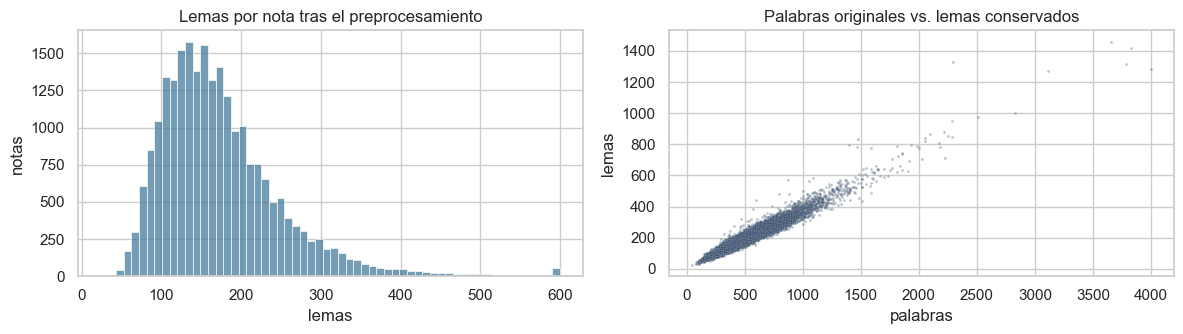

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(df["n_lemas"].clip(upper=600), bins=60, ax=axes[0], color="#457b9d")
axes[0].set(title="Lemas por nota tras el preprocesamiento", xlabel="lemas", ylabel="notas")
sns.scatterplot(x=df["n_palabras"], y=df["n_lemas"], s=4, alpha=0.3, ax=axes[1], color="#1d3557")
axes[1].set(title="Palabras originales vs. lemas conservados", xlabel="palabras", ylabel="lemas")
fig.tight_layout()

## 7. Exportación

Además del parquet, guardamos las stopwords del dominio y las frases detectadas. Así otros notebooks (o tú, al escribir la narrativa) pueden consultar exactamente qué se hizo.

In [19]:
df = df.drop(columns=["es_corta"])  # ya no quedan notas cortas
df.to_parquet(SALIDA, engine="pyarrow", compression="zstd", index=False)

(RAIZ / "data" / "processed" / "stopwords_dominio.txt").write_text("\n".join(sorted(STOP_DOMINIO)), encoding="utf-8")
frases.to_csv(RAIZ / "data" / "processed" / "frases.csv", index=False)

print(f"{SALIDA.relative_to(RAIZ)}: {len(df):,} notas, {df.shape[1]} columnas, {SALIDA.stat().st_size / 1e6:.0f} MB")

data/processed/noticias_base.parquet: 23,811 notas, 28 columnas, 98 MB


In [20]:
leido = pd.read_parquet(SALIDA)
assert len(leido) == len(df) and leido["id"].is_unique
assert leido["lemas_frases"].map(len).equals(df["lemas_frases"].map(len))
print("Verificación OK")
leido[["id", "fecha", "titulo", "es_plantilla", "n_lemas", "lemas_frases"]].head()

Verificación OK


,id,fecha,titulo,es_plantilla,n_lemas,lemas_frases
0,14264,2013-01-01,Desarrollan alumnos técnica aprobada por OMS para un mejor diagnóstico del lupus,False,156,"[desarrollan, alumno, técnico, aprobado, oms, diagnóstico, lupus, estudiantes, químico_biológicas, trabajar, proyect..."
1,14265,2013-01-02,Registro en línea para examen de colocación de inglés será el 4 de enero de 2013,False,107,"[registro, línea, examen_colocación, inglés, enero, lenguas_extranjeras, emitir, convocatoria, inscripción_reinscrip..."
2,14266,2013-01-03,Interesa en Brasil Sistema de Servicios Sustentables que desarrollan académicos de Unison,False,163,"[interesar, brasil, sistema, servicios, sustentables, desarrollar, empresarios, ramo, automotriz, dedicado, reparaci..."
3,14267,2013-01-03,Aplica académico el enfoque psicológico a la sustentabilidad,False,115,"[aplicar, enfoque, psicológico, sustentabilidad, enfoque, psicológico, sustentabilidad, permitir, enfrentar, abordar..."
4,14268,2013-01-04,Serán del 7 al 11 de enero las reinscripciones generales para semestre 2013-1,False,103,"[enero, reinscripción, general, semestre, proceso, reinscripción, semestre, enero, trámite, campus, alma_mater, dire..."


## Uso

```python
import pandas as pd
df = pd.read_parquet("../data/processed/noticias_base.parquet")

# Para modelado de temas: sin plantillas, tokens con frases unidas
corpus = df.loc[~df["es_plantilla"], "lemas_frases"]

# Para NER o embeddings: texto limpio con mayúsculas y puntuación
textos = df["texto_limpio"]
```

**Siguiente paso:** la capa específica de la historia elegida.